<a href="https://colab.research.google.com/github/HarjapP/4010Project/blob/main/aise_project_group8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

print("Hello World!")

Hello World!


In [ ]:
import sys
import numpy as np
import pandas as pd
import torch
import sklearn
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("Python environment:", sys.executable)
print("All libraries working!")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python environment: /usr/bin/python3
All libraries working!


In [ ]:
print("Test 1")

Test 1


In [ ]:
print("Can you see me?")

Can you see me?


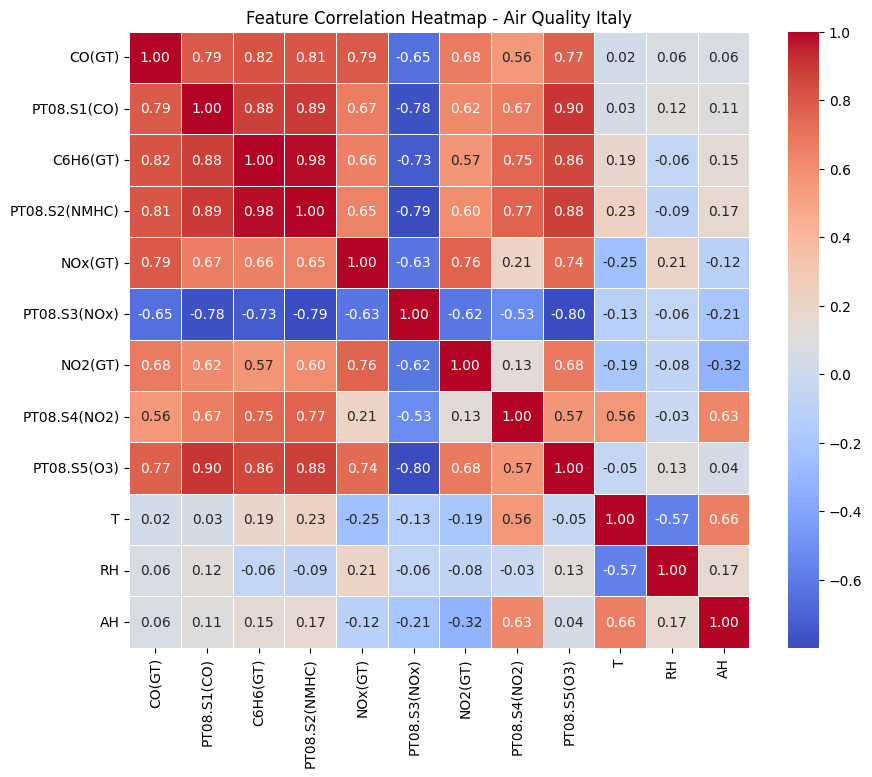

Target variable selected: C6H6(GT)
Lookback window: 72 hours | Forecast horizon: 24 hours


In [ ]:
# 1. Load Dataset (assuming 'AirQualityUCI.csv' is uploaded to Colab)
# Note: UCI dataset uses semicolon separators and comma decimals in some versions
df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',', low_memory=False)

# Drop trailing empty columns if present due to trailing semicolons in CSV
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# 2. Combine Date and Time into Datetime Index
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H.%M.%S', errors='coerce')
df = df.dropna(subset=['DateTime'])
df = df.set_index('DateTime')
df = df.drop(columns=['Date', 'Time'])

# 3. Handle Missing Values (-200 tag)
df = df.replace(-200, np.nan)

# 4. Drop columns with excessive missingness (NMHC(GT))
if 'NMHC(GT)' in df.columns:
    df = df.drop(columns=['NMHC(GT)'])

# Impute remaining missing values using linear interpolation for time series
df = df.interpolate(method='linear').bfill().ffill()

# 5. Correlation Heatmap for Target Selection
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap - Air Quality Italy')
plt.show()

# 6. Define Target Variable, Lookback (L=72), and Horizon (h=24)
TARGET_COL = 'C6H6(GT)'
LOOKBACK = 72
HORIZON = 24

print(f"Target variable selected: {TARGET_COL}")
print(f"Lookback window: {LOOKBACK} hours | Forecast horizon: {HORIZON} hours")